In [1]:
# Make the project importable whether this runs from notebooks/ or the repo root.
import pathlib
import sys

_root = next(
    p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    if (p / "src" / "__init__.py").exists()
)
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

# 05 · Feast Locally

**The real tool, no server.** Everything so far was hand-built. Now we stand up a genuine
[Feast](https://feast.dev) feature store — but entirely **local and keyless**: `provider: local`,
a file offline store and a SQLite online store, **no server, no Docker, no account**. We run
`apply`, `get_historical_features`, `materialize`, and `get_online_features`, and we prove Feast
produces the **same point-in-time training set** as our hundred-line store.

The point: Feast is the hundred-line idea done properly. You learn the tool by *recognising* it.

In [2]:
import tempfile
from pathlib import Path

from src.artifacts import apply_style, save_figure, save_json, BLUE, MUTED, GOOD
from src.config import settings, ENTITY_COL, EVENT_TS_COL, FEATURE_COL
from src.datasets.events import load
import matplotlib.pyplot as plt

apply_style()

try:
    import feast
    HAVE_FEAST = True
    print("feast version:", feast.__version__)
except ImportError:
    HAVE_FEAST = False
    print("Feast not installed — run `uv sync --all-extras`. This notebook needs it.")

ds = load(settings)

feast version: 0.67.0


## Parity: Feast vs the hundred-line store

`src.evaluation.parity.compare` builds a throwaway local Feast store over the **same**
`feature_history`, runs its point-in-time join, and lines it up against our mini-store's join,
row for row. We compare the feature values directly.

In [3]:
from src.evaluation.parity import compare

workdir = Path(tempfile.mkdtemp(prefix="fs101_feast_"))
sample = ds.events.head(200)
merged = compare(ds.feature_history, sample, workdir / "parity_repo")

mine = merged[f"{FEATURE_COL}_ministore"].to_numpy()
feast_vals = merged[f"{FEATURE_COL}_feast"].to_numpy()
max_abs_diff = int(abs(mine - feast_vals).max())
all_equal = bool((mine == feast_vals).all())
print(f"rows compared : {len(merged)}")
print(f"identical     : {all_equal}")
print(f"max |diff|    : {max_abs_diff}")
merged[[ENTITY_COL, f"{FEATURE_COL}_ministore", f"{FEATURE_COL}_feast"]].head()

rows compared : 200
identical     : True
max |diff|    : 0


,customer_id,txn_count_30d_ministore,txn_count_30d_feast
0,0,18,18
1,1,33,33
2,2,10,10
3,3,6,6
4,4,4,4


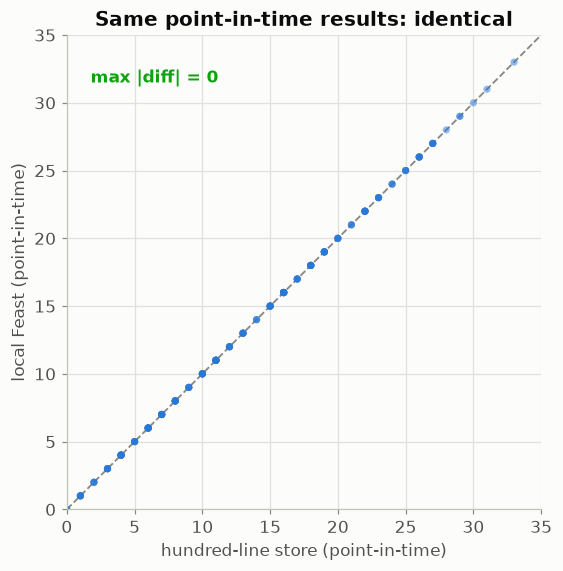

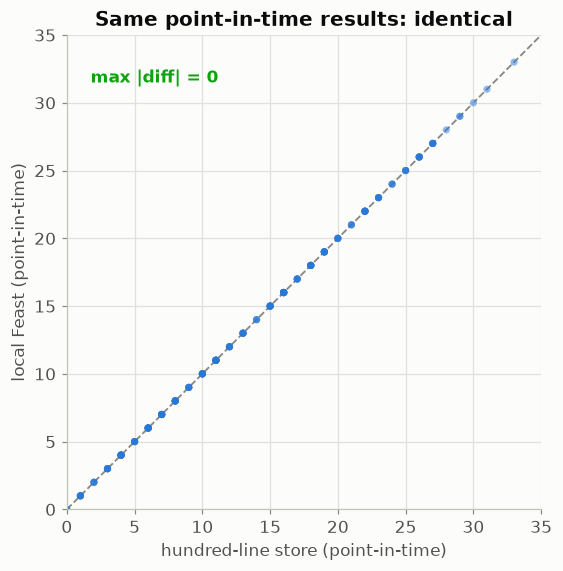

In [4]:
lim = max(mine.max(), feast_vals.max()) + 2
fig, ax = plt.subplots(figsize=(5.6, 5.6))
ax.plot([0, lim], [0, lim], color=MUTED, ls="--", lw=1.2, zorder=0)
ax.scatter(mine, feast_vals, s=22, color=BLUE, alpha=0.5, edgecolor="none")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_aspect("equal")
ax.set_xlabel("hundred-line store (point-in-time)")
ax.set_ylabel("local Feast (point-in-time)")
verdict = "identical" if all_equal else f"max |diff| = {max_abs_diff}"
ax.set_title(f"Same point-in-time results: {verdict}")
ax.text(lim * 0.05, lim * 0.9, f"max |diff| = {max_abs_diff}", color=GOOD, fontweight="bold")
save_figure(fig, "05_parity_scatter")
fig

## The full local workflow: apply → materialize → serve

`src.feast_demo.run_feast.demo` runs the whole loop against a local store: `apply` registers the
entity and feature view, `get_historical_features` builds the training set, `materialize` pushes
the latest values into SQLite, and `get_online_features` serves them — all in-process.

In [5]:
from src.feast_demo.run_feast import demo

out = demo(ds.feature_history, ds.events.head(50), workdir / "demo_repo")
print("historical (point-in-time training set):")
display(out["historical"].head())
print("online (latest, served from SQLite):")
display(out["online"].head())

Materializing 1 feature views from 2024-01-01 00:00:00+00:00 to 2024-06-28 00:00:00+00:00 into the sqlite online store.

customer_txn:


historical (point-in-time training set):


,customer_id,event_timestamp,txn_count_30d
0,34,2024-02-13 00:00:00+00:00,24
1,29,2024-02-15 00:00:00+00:00,15
2,19,2024-02-22 00:00:00+00:00,19
3,46,2024-02-22 00:00:00+00:00,4
4,40,2024-02-25 00:00:00+00:00,6


online (latest, served from SQLite):


,customer_id,txn_count_30d
0,0,27
1,1,29
2,2,16
3,3,5
4,4,6


## What Feast adds on top of the hundred lines

Our store and Feast agree on the core (point-in-time join + online lookup). Feast adds the
operational layer you would otherwise rebuild:

- a **managed registry** with versioned feature definitions and a CLI (`feast apply`),
- **materialization and freshness** (TTLs, incremental materialize) — the serving-side of drift,
- **scalable offline retrieval** (file/DuckDB/warehouse backends) for point-in-time over large histories,
- **online serving infrastructure** (SQLite locally; Redis/DynamoDB in production),
- **feature reuse and governance** across many models and teams — the value that most justifies a store.

In [6]:
payload = {
    "feast_available": HAVE_FEAST,
    "feast_version": getattr(feast, "__version__", None) if HAVE_FEAST else None,
    "parity": {
        "rows_compared": int(len(merged)),
        "identical": all_equal,
        "max_abs_diff": max_abs_diff,
    },
    "config": {"provider": "local", "offline_store": "file", "online_store": "sqlite",
               "server": False, "docker": False, "account": False},
    "what_feast_adds": [
        "managed, versioned registry + CLI (feast apply)",
        "materialization and freshness (TTLs)",
        "scalable offline retrieval (file/DuckDB/warehouse)",
        "online serving infrastructure (SQLite -> Redis/DynamoDB)",
        "feature reuse and governance across teams",
    ],
}
print(save_json(payload, "05_feast_parity"))
payload["parity"]

/workspaces/feature_store_101/outputs/json/05_feast_parity.json


{'rows_compared': 200, 'identical': True, 'max_abs_diff': 0}

## Next

**[06 · Decision Framework](06_decision_framework.ipynb)** — do you even need a feature store?
When a dataframe suffices, when Feast earns its keep, and the rule that outranks the tool choice.